In [1]:
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))

from config import config

In [2]:
csvs_path_2025 = config.EXTRACTED / "ECV_2025_extracted" / "csv"

In [3]:
files_2025_csv = []
paths_2025_files = {}
for file in os.listdir(csvs_path_2025):
    ruta_completa = os.path.join(csvs_path_2025, file)

    # Verificar que sea un archivo (y no una carpeta)
    if not os.path.isfile(ruta_completa) or Path(ruta_completa).suffix not in (
        ".csv",
        ".CSV",
    ):
        print("no es csv o archvio")

    else:
        paths_2025_files[file] = ruta_completa

In [4]:
len(paths_2025_files)

17

In [5]:
cantidad_nulos_por_df = {}
for name, path in paths_2025_files.items():
    temp_df = pd.read_csv(path, sep=";")
    n_nulls = temp_df.isna().sum().sum()
    cantidad_nulos_por_df[name] = n_nulls
    print(f"{name}")
    print(f"Numero nulos: {n_nulls}")
    print("=" * 30)
    # display(temp_df.head(3))

Adquisición de bienes y servicios por ítem.CSV
Numero nulos: 0
Adquisición de bienes y servicios.csv
Numero nulos: 1367233
Atención integral de los niños y niñas menores de 5 años.csv
Numero nulos: 591117
Características y composición del hogar.csv
Numero nulos: 10507991
Condiciones de vida del hogar y tenencia de bienes (programas).csv
Numero nulos: 0
Condiciones de vida del hogar y tenencia de bienes.csv
Numero nulos: 4629810
Datos de la vivienda.csv
Numero nulos: 442172
Educación.csv
Numero nulos: 14168309
FEX_PDET_VIV_2025.csv
Numero nulos: 0
Fuerza de trabajo.csv
Numero nulos: 14550260
Salud.csv
Numero nulos: 25300160
Servicios del hogar.csv
Numero nulos: 3252828
Tecnologías de información y comunicación.csv
Numero nulos: 12253846
Tenencia y financiacion de la vivienda que ocupa el hogar (personas escritura).csv
Numero nulos: 0
Tenencia y financiacion de la vivienda que ocupa el hogar.csv
Numero nulos: 1133170
Trabajo infantil.csv
Numero nulos: 41665
Variables diseño muestral.csv


In [6]:
np.mean(list(cantidad_nulos_por_df.values()))

np.float64(5190503.588235294)

# Buscar como consolidad la informacion, despues reevaluar nulos

variables candidatas de la encuesta para replicar el paper

| Dimensión | Indicador (paper) | Archivo ECV 2023 | Variable(s) |
| --- | --- | --- | --- |
| **Ingreso** | Ingreso per cápita | Servicios del hogar (**F2**) | `PERCAPITA` (también `I_HOGAR`, `I_UGASTO`) |
| **Salud** | ~BMI~ | — | — |
| **Salud** | Salud autopercibida | Salud (**F43**) | `P6127` |
| **Salud** | Seguro médico | Salud (**F43**) | `P6090`; complemento `P6100` (régimen) |
| **Educación** | Nivel educativo | Educación (**F24**) | `P8587` + `P8587S1` |
| **Educación** | Asistencia escolar | Educación (**F24**) + `P6040` (**F9**) | `P8586` |
| **Est. vida** | Combustible para cocinar | Servicios del hogar (**F2**) | `P8536` |
| **Est. vida** | Agua potable | Servicios del hogar (**F2**) | `P5069` (beber); alternativa `P8530` (preparar alimentos) |
| **Est. vida** | Propiedad de la vivienda | Tenencia y financiación (**F3**) | `P5095` "La vivienda ocupada por este hogar es:" |
| **Est. vida** | Área per cápita | Servicios del hogar (**F2**) | `CANT_PERSONAS_HOGAR` / `P5010` |
| **Est. vida** | Bienes durables | Condiciones de vida y bienes (**F51**) | `P1077S1` ... `P1077S30` |

## Buscar cuales son los identifdicadores de un hogar dentro de los archivos


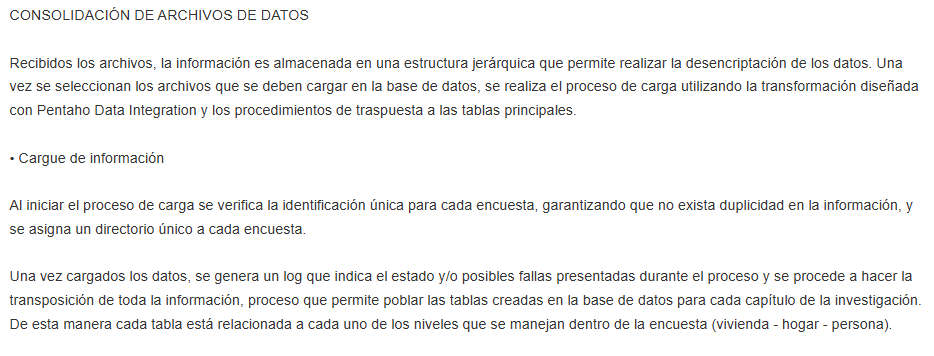
extraido de: https://microdatos.dane.gov.co/index.php/catalog/905/study-description

In [7]:
df_servicios = pd.read_csv(
    paths_2025_files["Servicios del hogar.csv"],
    sep=";",
)

df_design = pd.read_csv(
    paths_2025_files["Variables diseño muestral.csv"], sep=";"
)

## Examinar archivo de diseño muestral, primer acercamiento a identificar personas

In [8]:
df_design.head(4)

,DIRECTORIO,SECUENCIA_P,ORDEN,MPIO,SEGMENTO,ESTRATO2020,F2,F_ETAPA1,FRES,FEX_C,BLOQUE
0,8369550,1,1,13001,10394,1398,1,"367,6951571","367,6951571","472,1319013",A00013
1,8369550,1,2,13001,10394,1398,1,"367,6951571","367,6951571","472,1319013",A00013
2,8369550,1,3,13001,10394,1398,1,"367,6951571","367,6951571","472,1319013",A00013
3,8369550,1,4,13001,10394,1398,1,"367,6951571","367,6951571","472,1319013",A00013


In [9]:
df_design["SECUENCIA_P"].unique()

array([1, 2, 3, 4, 5, 6])

In [10]:
# Contar la cantidad de parejas únicas
parejas_unicas = (
    df_design[["DIRECTORIO", "SECUENCIA_P", "ORDEN"]]
    .drop_duplicates()
    .shape[0]
)  # vivienda, hogar, persona

print(f"Total de parejas únicas: {parejas_unicas}")

Total de parejas únicas: 235350


In [11]:
234896 == 235350

False

In [12]:
df_design["DIRECTORIO"].nunique()  # 86848 viviendas

86848

In [13]:
df_servicios.shape[0] - df_servicios["DIRECTORIO"].nunique()

212

**DIRECTORIO identifica los inmuebles encuestados**, por eso los duplicados, hay varios hogares (familias) en el mismo inmueble, nuestro estudio es a nivel hogar.
Sin embargo hemos de consolidar datos de los integrantes a nivel persona.

Ademas los resultados de la celda de abajo son consistentes con lo que reporta la ECV 2025, **86.848 viviendas** y **87.060 hogares**, varios hogares comparten la misma vivienda, puede ser un indicador interesate, aunque son pocos los casos (212 viviendas compartidas).

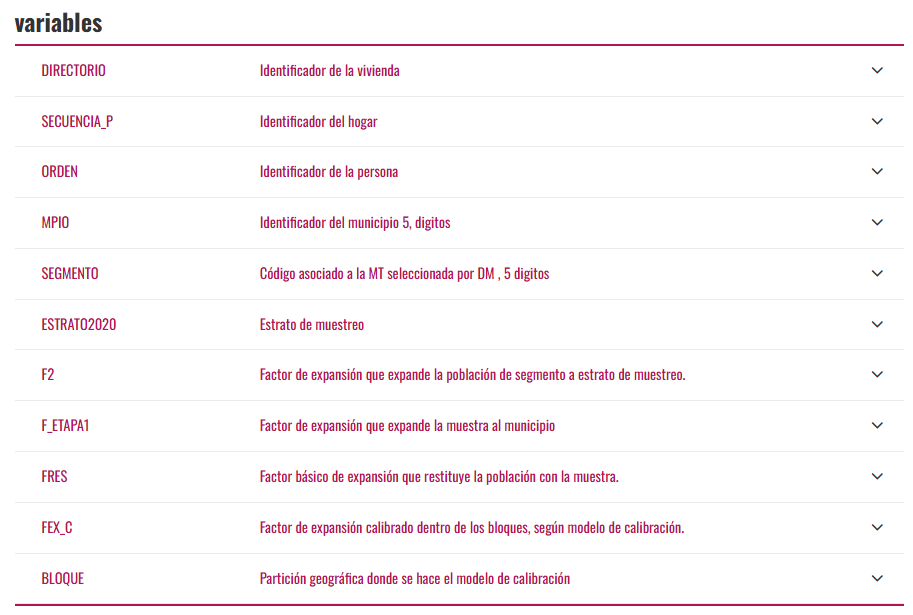

## Examinar archivo a nivel hogar

In [14]:
df_servicios.columns

Index(['DIRECTORIO', 'SECUENCIA_ENCUESTA', 'SECUENCIA_P', 'ORDEN', 'FEX_C',
       'P5000', 'P5010', 'P791', 'P5018', 'P5018S1', 'P5018S2', 'P9003',
       'P9004', 'P5666', 'P3162', 'P3163', 'P3163S1', 'P3163S2', 'P8526',
       'P3164', 'P5022', 'P5024', 'P5030', 'P5032', 'P5034', 'P5034S1',
       'P5034S2', 'P1892', 'P1892S1', 'P1892S2', 'P1892S3', 'P1892S4', 'P3165',
       'P5041', 'P5038', 'P5044', 'P5044S1', 'P5044S2', 'P5046', 'P5046S1',
       'P5046S1A1', 'P5046S1A2', 'P5046S1A3', 'P5046S1A4', 'P5046S1A5',
       'P5046S1A6', 'P5046S1A7', 'P5012', 'P5012S1', 'P5012S2', 'P5012S3',
       'P5012S8', 'P5012S4', 'P5012S5', 'P5012S6', 'P5012S7', 'P792', 'P5067',
       'P5067S1', 'P5067S2', 'P8530', 'P5047', 'P3177', 'P3166', 'P3167',
       'P3168', 'P5069', 'P764', 'P8534', 'P3169', 'P3169S1', 'P3169S2',
       'P3169S3', 'P3169S4', 'P8536', 'P1698', 'P1698S1', 'P8540', 'P8540S1',
       'P5305', 'P3171', 'P3172', 'P3172S1', 'P3172S2', 'P3172S3', 'P3172S4',
       'P3173', 'P31

In [15]:
for k in [
    ["DIRECTORIO"],
    ["DIRECTORIO", "SECUENCIA_ENCUESTA"],
    ["DIRECTORIO", "SECUENCIA_P"],
    ["DIRECTORIO", "ORDEN"],
    ["DIRECTORIO", "SECUENCIA_ENCUESTA", "SECUENCIA_P"],
]:
    print(k, df_servicios.duplicated(subset=k).sum())

['DIRECTORIO'] 212
['DIRECTORIO', 'SECUENCIA_ENCUESTA'] 0
['DIRECTORIO', 'SECUENCIA_P'] 212
['DIRECTORIO', 'ORDEN'] 0
['DIRECTORIO', 'SECUENCIA_ENCUESTA', 'SECUENCIA_P'] 0


In [16]:
df_servicios["SECUENCIA_P"].unique()

array([1])

In [17]:
df_servicios["SECUENCIA_ENCUESTA"].unique()

array([1, 2, 3, 4, 5, 6])

In [18]:
df_servicios["ORDEN"].unique()

array([1, 2, 3, 4, 5, 6])

In [19]:
# Devuelve True si todas las parejas coinciden en el DataFrame
son_iguales = (
    df_servicios["SECUENCIA_ENCUESTA"] == df_servicios["ORDEN"]
).all()
print("¿Las parejas son totalmente iguales?:", son_iguales)

¿Las parejas son totalmente iguales?: True


In [20]:
parejas_unicas = (
    df_servicios[["DIRECTORIO", "SECUENCIA_ENCUESTA"]]
    .drop_duplicates()
    .shape[0]
)

print(f"Total de parejas únicas: {parejas_unicas}")

Total de parejas únicas: 87060


Aparentemente `SECUENCIA_ENCUESTA` y `ORDEN` contienen la misma informacion de identificacion y `SECUENCIA_P` no es mas que una constante en 1.

A priori `ORDEN` puede parecer inutil, por lo menos en este archivo, pero la documentacion reporta que es un identificador unico por persona. Se evaluara su utilidad en archivos a nivel de persona.

en algunos archivos `SECUENCIA_P` si contiene info, probablemente con un uso similar a `SECUENCIA_ENCUESTA` que se validara despues, solo hay evidencia de ese uso en el design, hasta el momento. Para buscar consistencia se trata de usar siempre `SECUENCIA_ENCUESTA`.

**la convención no es la misma en todos los archivos.**

In [21]:
# Escrito por claude

KH_serv = ["DIRECTORIO", "SECUENCIA_ENCUESTA"]
KH_dsgn = ["DIRECTORIO", "SECUENCIA_P"]

# 1. ¿El archivo de diseño tiene los mismos 87.060 hogares?
print(df_design[KH_dsgn].drop_duplicates().shape[0])  # esperado 87060

# 2. ¿Coinciden hogar por hogar?
h_serv = df_servicios[KH_serv].rename(columns={"SECUENCIA_ENCUESTA": "ID_HOG"})
h_dsgn = (
    df_design[KH_dsgn]
    .drop_duplicates()
    .rename(columns={"SECUENCIA_P": "ID_HOG"})
)
chk = h_serv.merge(
    h_dsgn, on=["DIRECTORIO", "ID_HOG"], how="outer", indicator=True
)
print(chk._merge.value_counts())  # todo "both"

# 3. Prueba decisiva: personas por hogar vs CANT_PERSONAS_HOGAR
n = df_design.groupby(KH_dsgn).size().rename("n_per").reset_index()
n = n.rename(columns={"SECUENCIA_P": "ID_HOG"})
cmp_ = df_servicios.rename(columns={"SECUENCIA_ENCUESTA": "ID_HOG"})[
    ["DIRECTORIO", "ID_HOG", "CANT_PERSONAS_HOGAR"]
].merge(n, on=["DIRECTORIO", "ID_HOG"], how="outer", indicator=True)
print((cmp_.CANT_PERSONAS_HOGAR == cmp_.n_per).mean())  # debe ser 1.0

87060
_merge
both          87060
left_only         0
right_only        0
Name: count, dtype: int64
1.0


## Examinar a nivel persona

In [ ]:
df_salud = pd.read_csv(
    paths_2025_files["Salud.csv"], sep=";", encoding="latin-1"
)
print(len(df_salud))  # 235.350 personas

235350


In [23]:
for k in [
    ["DIRECTORIO", "SECUENCIA_ENCUESTA"],
    ["DIRECTORIO", "ORDEN"],
    ["DIRECTORIO", "SECUENCIA_ENCUESTA", "ORDEN"],
    ["DIRECTORIO", "SECUENCIA_ENCUESTA", "SECUENCIA_P"],
    ["DIRECTORIO", "SECUENCIA_ENCUESTA", "ORDEN"],
]:
    print(k, df_salud.duplicated(subset=k).sum())

['DIRECTORIO', 'SECUENCIA_ENCUESTA'] 454
['DIRECTORIO', 'ORDEN'] 454
['DIRECTORIO', 'SECUENCIA_ENCUESTA', 'ORDEN'] 454
['DIRECTORIO', 'SECUENCIA_ENCUESTA', 'SECUENCIA_P'] 0
['DIRECTORIO', 'SECUENCIA_ENCUESTA', 'ORDEN'] 454


In [ ]:
KH_serv = ["DIRECTORIO", "SECUENCIA_ENCUESTA"]  # hogar en F2
KH_salud = ["DIRECTORIO", "SECUENCIA_P"]  # hogar en F43

# ¿ORDEN y SECUENCIA_ENCUESTA son la misma persona en Salud?
print(all(df_salud["ORDEN"] == df_salud["SECUENCIA_ENCUESTA"]))

conteo = (
    df_salud.groupby(KH_salud)
    .size()
    .rename("n_personas")
    .reset_index()
    .rename(columns={"SECUENCIA_P": "ID_HOG"})
)

serv = df_servicios[KH_serv + ["CANT_PERSONAS_HOGAR"]].rename(
    columns={"SECUENCIA_ENCUESTA": "ID_HOG"}
)

chk = serv.merge(
    conteo, on=["DIRECTORIO", "ID_HOG"], how="outer", indicator=True
)
print(chk._merge.value_counts())  # todo "both"
print((chk.CANT_PERSONAS_HOGAR == chk.n_personas).mean())  # debe dar 1.0

True
_merge
both          87060
left_only         0
right_only        0
Name: count, dtype: int64
1.0


Con el analisis de los archivos hasta el momento se tiene que el identificador de vivienda es `["DIRECTORIO"]`, el de hogar `["DIRECTORIO", "SECUENCIA_ENCUESTA"]` y el de persona `["DIRECTORIO","SECUENCIA_ENCUESTA","SECUENCIA_P"]`, a pesar de no ser lo que reporta la ECV en su documentación es el cruce que se ha encontrado que deja reelaciones 1 a 1, elimina duplicados y mantiene la consistencia entre tablas.

# **REVISAR ESE ANALISIS**